# Example: A Covered Call Fund on a Hypothetical Stock
In this example, we simulate a covered call fund, in the style of FEPI, for a hypothetical stock `XYZ`.

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
> * __Simulate monthly share prices:__ Simulate one year of monthly share prices with geometric Brownian motion, using the drift and volatility estimated from historical data.
> * __Price and roll a covered call:__ Price a one-month out-of-the-money American call on the binomial tree at the start of each month, and compute the fund's growth when the calls expire worthless or are exercised, buying new shares after an exercise from the fund's cash or by borrowing.
> * __Compare the covered call fund with the benchmark:__ Compare the distributions of one-year growth rates, and explain how the premiums cushion losses and the sold calls give up gains.

We compare the fund's one-year growth rate with that of a benchmark that holds the same shares and opens with the same cash but sells no calls.

Let's get started!
___

## Setup, Data, and Prerequisites
First, we set up the computational environment by including the `Include.jl` file and loading any needed resources.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates the contents of the input source file, `Include.jl`, in the notebook's global scope. The `Include.jl` file sets paths, loads required external packages, etc. For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/).

Let's set up our code environment:

In [1]:
include(joinpath(@__DIR__, "Include.jl")); # include the Include.jl file

  Activating project at `~/Desktop/julia_work/CHEME-5660-CourseRepository-Fall-2026`


For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/) and the [CHEME 5660 Quantitative Finance Package documentation](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/).

### Data
We'll simulate the share price with geometric Brownian motion (GBM). Let's load the single asset geometric Brownian motion (SAGBM) parameters which we estimated a few lectures ago, which include the drift and volatility for each ticker. We'll store this data in the `parameters_df::DataFrame` variable:

In [2]:
parameters_df = let

    # load the GBM parameters estimated from the 2014 to 2024 training data, one row per ticker -
    df = CSV.read(joinpath(_PATH_TO_DATA, "SAGBM-Parameters-Fall-2025.csv"), DataFrame);

    # return -
    df
end;

### Constants
Next, let's set the constants. See the comments next to the constants for definitions, units, and permissible values.

In [3]:
# the shares the fund holds, and the simulation -
ticker = "SPY"; # ticker whose drift and volatility we use (any ticker in parameters_df works)
stock = "XYZ"; # the hypothetical stock the fund holds; it has the drift and volatility of ticker
Sₒ = 100.0; # share price of the hypothetical stock when the fund opens (USD/share)
number_of_months = 12; # how long we run the fund (months); we sell calls at the start of each month
number_of_paths = 10000; # number of simulated share price paths
Δt = 1/12; # one month, the life of each call (years)
random_seed = 5660; # fix the random numbers, so every run gives the same paths

# the calls the fund sells at the start of each month -
m = 100; # shares per contract (listed options)
number_of_contracts = 10; # calls the fund sells every month; it holds m*number_of_contracts shares (the growth rates do not depend on it)
cash_reserve = 0.05; # cash the fund holds when it opens, as a fraction of the value of its shares
moneyness = 1.02; # target strike over the share price at the start of the month, K/S (1.00 = at the money)
strike_increment = 0.50; # listed strikes are this far apart (USD/share); the fund sells the smallest listed strike at or above moneyness*S
σ_scale = 1.0; # price the calls at this multiple of the historical volatility (try 1.2 for a higher implied volatility)
h = 60; # number of steps in the binomial tree that prices each call

# the risk-free rate, from the 13-week Treasury bill -
τ_bill = 91/365; # term of the 13-week Treasury bill (years)
y_bill = 0.0415; # 13-week bill coupon-equivalent yield on 2026-10-26, U.S. Treasury Daily Treasury Bill Rates
gᵧ = log(1 + y_bill*τ_bill)/τ_bill; # continuously compounded risk-free rate (1/yr)
𝒟 = exp(gᵧ*Δt); # accumulation factor over one month (dimensionless)

# checks -
@assert moneyness > 0 "the strike must be positive, so moneyness = K/S must be positive"
@assert strike_increment > 0 "listed strikes must be a positive distance apart"
@assert number_of_months ≥ 1 && number_of_paths ≥ 1 "we need at least one month and one path"
@assert number_of_contracts ≥ 1 && cash_reserve ≥ 0 "the fund needs at least one contract and a nonnegative cash reserve"

Finally, let's look up the drift and the volatility of `SPY`, which we use for `XYZ`. As in the earlier examples, the `drift` column is the mean growth rate $\hat{\mu}_{g}$, so the GBM drift is $\hat{\mu}=\hat{\mu}_{g}+\hat{\sigma}^{2}/2$:

In [4]:
μ̂, σ̂ = let

    # initialize: the row of parameters_df for our ticker -
    row = only(eachrow(filter(:ticker => ==(ticker), parameters_df))); # fails if the ticker is missing
    μ̂_g = row.drift; # mean growth rate (1/yr)
    σ̂ = row.volatility; # historical volatility (1/sqrt(yr))
    μ̂ = μ̂_g + σ̂^2/2; # GBM drift (1/yr)

    # show the parameters -
    println("$(ticker): μ̂_g = $(round(μ̂_g, digits = 4)), σ̂ = $(round(σ̂, digits = 4)), μ̂ = $(round(μ̂, digits = 4)) (1/yr)");
    println("risk-free rate gᵧ = $(round(gᵧ, digits = 4)) (1/yr), monthly accumulation factor 𝒟 = $(round(𝒟, digits = 5))");

    # checks -
    @assert σ̂ > 0 "the volatility must be positive"

    # return -
    (μ̂, σ̂)
end;

SPY: μ̂_g = 0.1031, σ̂ = 0.1351, μ̂ = 0.1123 (1/yr)
risk-free rate gᵧ = 0.0413 (1/yr), monthly accumulation factor 𝒟 = 1.00345


___

## Task 1: Simulate Monthly Share Prices
In this task, we simulate the share price of `XYZ` at the start of each month for one year. We use geometric Brownian motion with our historical drift $\hat{\mu}$ and volatility $\hat{\sigma}$, so these paths are our belief about the share price, not the risk-neutral model.

The [sample(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/equity/#VLQuantitativeFinancePackage.sample-Tuple{MyGeometricBrownianMotionEquityModel,%20NamedTuple}) returns one row per month and one column per path, with the time in the first column. We keep the share prices and store them in the `share_prices::Array{Float64,2}` variable: row $j$ holds the share price $S_{j}$ at the start of month $j$, and the last row holds the share price at the end of the year.

In [5]:
share_prices = let

    # initialize: the GBM model of the share price under our belief -
    Random.seed!(random_seed); # reproducible paths
    model = build(MyGeometricBrownianMotionEquityModel, (
        μ = μ̂, # drift (1/yr)
        σ = σ̂ # volatility (1/sqrt(yr))
    ));

    # simulate monthly prices from today to the end of the year -
    paths = VLQuantitativeFinancePackage.sample(model, (
        T₁ = 0.0, # start time (years)
        T₂ = number_of_months*Δt, # end time (years)
        Δt = Δt, # one month (years)
        Sₒ = Sₒ # share price today (USD/share)
    ), number_of_paths = number_of_paths); # rows are months; column 1 is the time, columns 2:end are the paths
    S = paths[:, 2:end]; # drop the time column: S[j, p] is the share price on path p at the start of month j

    # checks: one row per month plus the end of the year, one column per path, positive prices -
    @assert size(S) == (number_of_months + 1, number_of_paths) "unexpected size of the share price array"
    @assert all(S .> 0) "GBM share prices must be positive"

    # return -
    S
end;

`Unhide` the code block below to see how we plotted the first 50 simulated share price paths.

> __What do we see?__ Every path starts at the same share price. The spread of the paths grows with time, and some paths finish the year well below the starting price while others finish well above it. These are the outcomes the covered call fund and the benchmark will face.

What do the simulated share prices look like?

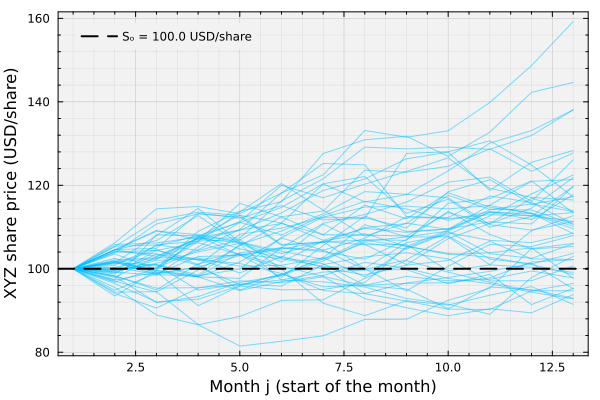

In [6]:
let

    # initialize: the months on the x-axis and how many paths to draw -
    months = 1:(number_of_months + 1); # month index j: S_j is the share price at the start of month j; the last value is the end of the year
    number_to_plot = min(50, number_of_paths); # draw at most 50 paths, so the plot stays readable

    # plot: each column of share_prices is one path -
    plot(months, share_prices[:, 1:number_to_plot], lw = 1, c = :deepskyblue1, alpha = 0.5, label = "",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        xminorticks = true, yminorticks = true, minorgrid = true)
    hline!([Sₒ], lw = 2, c = :black, ls = :dash, label = "Sₒ = $(Sₒ) USD/share") # the starting share price

    # labels -
    xlabel!("Month j (start of the month)", fontsize = 18)
    ylabel!("$(stock) share price (USD/share)", fontsize = 18)
end

___

## Task 2: Price and Roll the Covered Call
In this task, we run the fund month by month. The fund holds $mn$ shares, with $m=100$ shares per contract, and a cash account. At the start of each month, it sells $n$ calls, one contract for every $m$ shares. At the end of the month, the calls either expire worthless or are exercised, and the fund sells new calls for the next month.

At the start of month $j$, with share price $S_{j}$:
* __Strike:__ listed strikes are `strike_increment` apart, so the fund sells a one-month call with the smallest listed strike $K_{j}$ at or above $\text{moneyness}\cdot S_{j}$. With `moneyness = 1.02`, the call is at least 2% out of the money.
* __Premium:__ we price the American call on the CRR binomial tree with [the binomial_premium(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.binomial_premium), using the risk-free rate $g_{y}$ and the volatility $\hat{\sigma}$ (times `σ_scale`). The fund collects $\mathcal{P}_{c,j}$ per share and adds it to its cash account.
* __End of the month__ (start of month $j+1$): the fund's shares are worth $S_{j+1}$. We assume every call that finishes in the money ($S_{j+1}>K_{j}$) is exercised. Then the fund sells its shares to the call buyers at the strike $K_{j}$. To sell calls the next month, it then buys $mn$ new shares at $S_{j+1}$, so its cash falls by $S_{j+1}-K_{j}$ per share, the call's payoff.

Let's derive how the fund's wealth $W$ grows over month $j$. At the start of the month, before it sells the calls, the fund holds $mn$ shares and cash $C_{j}$ (USD), so $W_{j}=mn\cdot S_{j}+C_{j}$. The fund opens with a cash reserve, and when its cash runs out, it borrows, so $C_{j}<0$.

When the fund sells the calls, the premium $mn\cdot\mathcal{P}_{c,j}$ goes into its cash. Over the month, the cash, including the premium, earns the risk-free rate, and the fund pays the same rate on a loan, so at the end of the month:
$$
\underbrace{C_{j+1}}_{\text{end of month } j} = \underbrace{\mathcal{D}_{T,0}(g_{y})\cdot\left(C_{j}+mn\cdot\mathcal{P}_{c,j}\right)}_{\text{cash and premium grown for one month}} - \underbrace{mn\cdot\left(S_{j+1}-K_{j}\right)^{+}}_{\text{cost of new shares less strike received}}
$$
where $T$ is one month. The fund's wealth at the end of the month is its shares plus its cash. We substitute $C_{j+1}$ and collect the terms that are multiplied by $mn$:
$$
\begin{align*}
\underbrace{W_{j+1}}_{\text{end of month } j} &= \underbrace{mn\cdot S_{j+1}}_{\text{shares}} + \underbrace{C_{j+1}}_{\text{cash}}\\
&= mn\cdot S_{j+1} + \mathcal{D}_{T,0}(g_{y})\cdot\left(C_{j}+mn\cdot\mathcal{P}_{c,j}\right) - mn\cdot\left(S_{j+1}-K_{j}\right)^{+}\\
&= mn\cdot\left[\underbrace{S_{j+1}}_{\text{share price}}-\underbrace{\left(S_{j+1}-K_{j}\right)^{+}}_{\text{call payoff}}+\underbrace{\mathcal{D}_{T,0}(g_{y})\cdot\mathcal{P}_{c,j}}_{\text{premium grown for one month}}\right]+\underbrace{\mathcal{D}_{T,0}(g_{y})\cdot C_{j}}_{\text{cash grown for one month}}
\end{align*}
$$
For each share, the share minus the call payoff, $S_{j+1}-(S_{j+1}-K_{j})^{+}$, takes one of two values, the same two regimes as the lecture's covered call:
* __Call exercised__ ($S_{j+1}>K_{j}$): the payoff is $S_{j+1}-K_{j}$, so the share minus the payoff is $S_{j+1}-(S_{j+1}-K_{j})=K_{j}$. The fund sells each share to the call buyer for $K_{j}$, even though it is worth $S_{j+1}$.
* __Call expires worthless__ ($S_{j+1}\leq K_{j}$): the payoff is zero, so the share minus the payoff is $S_{j+1}$.

In both cases, $S_{j+1}-(S_{j+1}-K_{j})^{+}=\min(S_{j+1},K_{j})$. Dividing by $W_{j}$:
$$
\frac{\overbrace{W_{j+1}}^{\text{end of month } j}}{\underbrace{W_{j}}_{\text{start of month } j}} = \frac{mn\cdot\left[\min\left(S_{j+1},K_{j}\right)+\mathcal{D}_{T,0}(g_{y})\cdot\mathcal{P}_{c,j}\right]+\mathcal{D}_{T,0}(g_{y})\cdot C_{j}}{mn\cdot S_{j}+C_{j}}
$$
With no cash ($C_{j}=0$), the numerator is the lecture's covered call value at expiration, $\min(S_{j+1},K_{j})$, plus the premium grown for one month, per share. The fund opens with cash equal to `cash_reserve` times the value of its shares. We assume the fund borrows at the risk-free rate $g_{y}$, with no limit; a real fund pays more and faces borrowing limits.

__Benchmark:__ We compare the fund with a benchmark that holds the same $mn$ shares and the same opening cash, but sells no calls, so its cash only earns the risk-free rate.

We store the monthly wealth ratios in the `fund_ratio::Array{Float64,2}` and `benchmark_ratio::Array{Float64,2}` variables, the premiums in the `premiums::Array{Float64,2}` variable, and the cash in the `cash::Array{Float64,2}` variable:

In [7]:
fund_ratio, benchmark_ratio, premiums, cash = let

    # initialize: one row per month, one column per path -
    fund_ratio = zeros(number_of_months, number_of_paths); # W_{j+1}/W_j for the covered call fund
    benchmark_ratio = zeros(number_of_months, number_of_paths); # W_{j+1}/W_j for the benchmark: the same shares and opening cash, no calls
    premiums = zeros(number_of_months, number_of_paths); # call premium at the start of each month (USD/share)
    cash = zeros(number_of_months + 1, number_of_paths); # C_j: cash at the start of each month and at the end of the year (USD); negative means borrowed
    benchmark_cash = zeros(number_of_months + 1, number_of_paths); # the benchmark's cash, which only earns the risk-free rate (USD)
    N_S = m*number_of_contracts; # shares the fund holds, one for each share its calls cover (shares)

    # main loop: every month on every path -
    for p ∈ 1:number_of_paths
        cash[1, p] = cash_reserve*N_S*share_prices[1, p]; # opening cash reserve (USD)
        benchmark_cash[1, p] = cash[1, p]; # the benchmark opens with the same cash (USD)
        for j ∈ 1:number_of_months

            # the share price at the start and at the end of month j -
            S_start = share_prices[j, p]; # S_j (USD/share)
            S_end = share_prices[j + 1, p]; # S_{j+1} (USD/share)

            # the fund's wealth at the start of the month, before it sells the calls: shares plus cash -
            W_start = N_S*S_start + cash[j, p]; # W_j (USD)
            W_start_benchmark = N_S*S_start + benchmark_cash[j, p]; # benchmark wealth at the start of the month (USD)

            # the calls we sell at the start of the month -
            K = strike_increment*ceil(round(moneyness*S_start/strike_increment, digits = 8)); # smallest listed strike at or above moneyness*S_j (USD/share); round first so an exact multiple is not pushed up
            call = build(MyAmericanCallContractModel, (K = K, sense = -1, copy = 1, premium = 0.0)); # one short call
            𝒫 = binomial_premium(call; method = :crr, h = h, T = Δt, σ = σ_scale*σ̂, Sₒ = S_start, μ = gᵧ); # premium (USD/share)

            # the premium goes into the fund's cash -
            C = cash[j, p] + N_S*𝒫; # cash after selling the calls (USD)

            # over the month, the cash, including the premium, earns the risk-free rate (or the fund pays it on a loan) -
            C = 𝒟*C; # cash grown for one month (USD)

            # at the end of the month, after an exercise: sell the shares at K, buy new shares at S_end, so the cash falls by the call payoff -
            C = C - N_S*max(S_end - K, 0.0); # C_{j+1} (USD)
            cash[j + 1, p] = C; # store the fund's cash at the end of the month
            benchmark_cash[j + 1, p] = 𝒟*benchmark_cash[j, p]; # the benchmark sells no calls, so its cash only grows (USD)

            # the wealth at the end of the month: shares plus cash -
            W_end = N_S*S_end + cash[j + 1, p]; # W_{j+1} (USD)
            W_end_benchmark = N_S*S_end + benchmark_cash[j + 1, p]; # benchmark wealth at the end of the month (USD)

            # store the month -
            fund_ratio[j, p] = W_end/W_start; # W_{j+1}/W_j
            benchmark_ratio[j, p] = W_end_benchmark/W_start_benchmark; # benchmark
            premiums[j, p] = 𝒫; # premium per share
        end
    end

    # checks: positive premiums, positive wealth (so the fund can repay what it borrowed), and benchmark ratios that multiply to its final wealth -
    W = N_S .* share_prices .+ cash; # wealth at the start of each month and at the end of the year (USD)
    @assert all(premiums .> 0) "every call premium should be positive"
    @assert all(W .> 0) "the fund's wealth must stay positive, but its loan equals or exceeds the value of its shares"
    W_benchmark = N_S .* share_prices .+ benchmark_cash; # benchmark wealth at the start of each month and at the end of the year (USD)
    @assert all(isapprox.(vec(prod(benchmark_ratio, dims = 1)), W_benchmark[end, :] ./ W_benchmark[1, :])) "the benchmark ratios should multiply to its final wealth"

    # return -
    (fund_ratio, benchmark_ratio, premiums, cash)
end;

Let's follow one simulated path month by month (path `p` in the code below). For each month, the table shows the fund's cash at the start of the month (USD, negative when it has borrowed), the share price at the start and the end of the month, the target strike (`moneyness` times the share price), the listed strike $K_{j}$, the premium, whether the call was exercised, the exercise loss (what the fund gives up per share when the call buyer pays the strike for shares worth $S_{j+1}$), and the ratios $W_{j+1}/W_{j}$ for the fund and for the benchmark:

In [8]:
let

    # initialize: the first simulated path -
    p = 1; # path index; change it to follow a different simulated year
    S_start = share_prices[1:end-1, p]; # share price at the start of each month (USD/share)
    S_end = share_prices[2:end, p]; # share price at the end of each month (USD/share)
    target = moneyness .* S_start; # target strike, moneyness times the share price (USD/share)
    K = strike_increment .* ceil.(round.(target ./ strike_increment, digits = 8)); # listed strike of each month's call: the smallest at or above the target, as in Task 2 (USD/share)

    # build the table: one row per month -
    df = DataFrame(
        month = 1:number_of_months,
        cash = cash[1:end-1, p], # the fund's cash at the start of each month (USD); negative means borrowed
        S_start = S_start,
        target = target,
        K = K,
        premium = premiums[:, p],
        S_end = S_end,
        exercised = S_end .> K, # true if the calls finish in the money
        exercise_loss = max.(S_end .- K, 0.0), # what the fund gives up per share: the shares are worth S_end, but the call buyer pays K (USD/share)
        fund = fund_ratio[:, p],
        benchmark = benchmark_ratio[:, p]
    );

    # show the table -
    pretty_table(df; column_labels = ["month", "cash (USD)", "S start", "target", "K", "premium", "S end", "exercised", "exercise loss (USD/share)", "fund W(j+1)/W(j)", "benchmark W(j+1)/W(j)"],
        formatters = [fmt__printf("%.2f", [2, 3, 4, 5, 6, 7, 9]), fmt__printf("%.4f", [10, 11])],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);
end

 ------- ------------ --------- -------- -------- --------- -------- ----------- --------------------------- ------------------ -----------------------
  month   cash (USD)   S start   target        K   premium    S end   exercised   exercise loss (USD/share)   fund W(j+1)/W(j)   benchmark W(j+1)/W(j) 
 ------- ------------ --------- -------- -------- --------- -------- ----------- --------------------------- ------------------ -----------------------
      1      5000.00    100.00   102.00   102.00      0.87    99.66       false                        0.00             1.0053                  0.9969
      2      5895.17     99.66   101.65   102.00      0.77   101.30       false                        0.00             1.0230                  1.0158
      3      6689.17    101.30   103.32   103.50      0.83   104.06        true                        0.56             1.0284                  1.0262
      4      6984.12    104.06   106.15   106.50      0.81   106.09       false            

> __What do we see?__
>
> * __The premium:__ The premium changes from month to month, because the share price changes and because the listed strike sits a different distance above the target, `moneyness` times the share price. For the same share price, a listed strike closer to the target pays a larger premium.
> * __Cash:__ Each month, the premium adds to the fund's cash, and the cash earns interest (on a loan, the fund pays interest). After a call is exercised, the fund buys new shares for more than the strike it received. The cash drops only when this extra cost, the exercise loss, is larger than the premium plus interest; otherwise, it still grows. If the cash runs out, the fund borrows; the second table in Task 3 shows how often.
> * __Months the call is exercised:__ The fund gives up any gain above the strike, so its ratio is close to $K_{j}/S_{j}$ plus the premium divided by the share price. When the share price ends above the strike by more than the premium, the benchmark usually grows more. When it ends above the strike by less than the premium, the fund usually still grows more.
> * __Months the call expires worthless:__ The fund keeps its shares and the premium, so it usually grows more than the benchmark, by about the premium divided by the share price.

Your table will differ if you change the constants.
___

## Task 3: Compare One-Year Growth Rates
In this task, we compute the one-year growth rate of the fund and of the benchmark on every simulated path, and compare the two distributions across all the paths. As for a share price, the one-year growth rate of the fund's wealth (and the benchmark's wealth) is the sum of the monthly log ratios, divided by the time:
$$
g = \frac{1}{T}\ln\left(\frac{W_{N+1}}{W_{1}}\right) = \frac{1}{T}\sum_{j=1}^{N}\ln\left(\frac{W_{j+1}}{W_{j}}\right)
$$
where $N$ is the number of months and $T=N\Delta t$ (years).

We summarize the two distributions of $g$ (units: 1/yr): the mean, the standard deviation, three percentiles, and the probability of losing money ($g<0$).

In [9]:
fund_g, benchmark_g = let

    # initialize: the one-year growth rate on every path, the sum of the monthly log ratios divided by the time -
    T = number_of_months*Δt; # length of the simulation (years)
    fund_g = vec(sum(log.(fund_ratio), dims = 1)) ./ T; # covered call fund (1/yr)
    benchmark_g = vec(sum(log.(benchmark_ratio), dims = 1)) ./ T; # benchmark: the same shares and opening cash, no calls (1/yr)

    # summarize each distribution -
    # probability of a loss: g .< 0 is true (1) or false (0) on each path, so its mean is the fraction of paths with a loss, our estimate of the probability
    summary(g) = [mean(g), std(g), quantile(g, 0.05), median(g), quantile(g, 0.95), mean(g .< 0)]; # statistics of a set of growth rates
    df = DataFrame(
        statistic = ["mean", "standard deviation", "5th percentile", "median", "95th percentile", "probability of a loss, g < 0"],
        fund = summary(fund_g),
        benchmark = summary(benchmark_g)
    );

    # show the results -
    pretty_table(df; column_labels = ["one-year growth rate (1/yr)", "covered call fund", "benchmark (no calls)"],
        alignment = [:l, :r, :r], formatters = [fmt__printf("%.4f", [2, 3])],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);

    # checks: one growth rate per path for each -
    @assert length(fund_g) == number_of_paths && length(benchmark_g) == number_of_paths "one growth rate per path"

    # return -
    (fund_g, benchmark_g)
end;

 ------------------------------ ------------------- ----------------------
  one-year growth rate (1/yr)    covered call fund   benchmark (no calls) 
 ------------------------------ ------------------- ----------------------
  mean                                      0.0806                 0.0994
  standard deviation                        0.0909                 0.1296
  5th percentile                           -0.0754                -0.1141
  median                                    0.0847                 0.0994
  95th percentile                           0.2249                 0.3140
  probability of a loss, g < 0              0.1847                 0.2227
 ------------------------------ ------------------- ----------------------


> __What do we see?__
>
> * __Spread:__ The fund's growth rates have a smaller standard deviation, and its 5th and 95th percentiles sit closer together than those of the benchmark. The premiums lift the bad years, and the sold calls reduce the gains in the best years.
> * __Losses and gains:__ The fund is less likely to lose money over the year, but its 95th percentile is far below that of the benchmark. Compare the two means: the premiums do not make up for all the gains the calls give up.

How often does the fund grow faster than the benchmark, and how often does it borrow? Let's put these numbers in a second table:

In [10]:
let

    # initialize: the paths where the benchmark loses money, and the months that end with negative cash on each path -
    down = benchmark_g .< 0; # true on paths where the benchmark loses money
    months_negative = vec(sum(cash[2:end, :] .< 0, dims = 1)); # number of months (0 to number_of_months) that end with negative cash on each path
    borrows = months_negative .> 0; # true on paths where the cash goes negative at some point during the year

    # build the table: how often the fund grows faster than the benchmark, and how often and how long it borrows -
    # each probability is the mean of true (1) / false (0) values, so it is the fraction of paths where the condition holds, our estimate of the probability
    df = DataFrame(
        statistic = [
            "probability that the fund grows faster than the benchmark",
            "probability that the fund grows faster, when the benchmark loses money",
            "probability that the cash goes negative at some point during the year",
            "in years when the cash goes negative, median number of months that end with negative cash"
        ],
        value = [
            mean(fund_g .> benchmark_g),
            mean(fund_g[down] .> benchmark_g[down]),
            mean(borrows),
            median(months_negative[borrows]) # a whole number of months, unless the middle two paths differ
        ]
    );

    # checks: the benchmark loses money on some path, and the cash goes negative on some path, so every value is defined -
    @assert any(down) "the benchmark never loses money, so the conditional probability is undefined"
    @assert any(borrows) "the cash never goes negative, so the median number of months is undefined"

    # show the table: probabilities to four decimals, the median as a number of months -
    pretty_table(df; column_labels = ["statistic", "value"], alignment = [:l, :r],
        formatters = [(v, r, c) -> c == 2 ? (r == 4 ? (isinteger(v) ? string(Int(v)) : string(v)) : string(round(v, digits = 4))) : v],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);
end

 ------------------------------------------------------------------------------------------- --------
  statistic                                                                                    value 
 ------------------------------------------------------------------------------------------- --------
  probability that the fund grows faster than the benchmark                                   0.4145
  probability that the fund grows faster, when the benchmark loses money                      0.8563
  probability that the cash goes negative at some point during the year                       0.4321
  in years when the cash goes negative, median number of months that end with negative cash        5
 ------------------------------------------------------------------------------------------- --------


`Unhide` the code block below to see how we plotted the two distributions of one-year growth rates.

> __What do we see?__ The fund's distribution (red) is narrower than that of the benchmark (blue). Its left tail is shifted to the right by the premiums, and its right tail stops well short of the benchmark's right tail.

How do the two distributions compare?

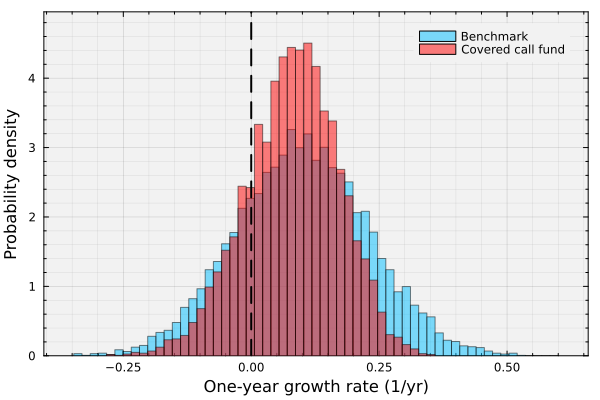

In [11]:
let

    # initialize: common bins, so the two histograms are comparable -
    lo = minimum([fund_g; benchmark_g]); # smallest growth rate on any path (1/yr)
    hi = maximum([fund_g; benchmark_g]); # largest growth rate on any path (1/yr)
    bins = range(lo, stop = hi, length = 60); # bin edges (1/yr)
    peak(g) = maximum([count(x -> bins[k] ≤ x < bins[k + 1], g) for k ∈ 1:(length(bins) - 1)])/(length(g)*step(bins)); # tallest bar of a probability density histogram
    ymax = 1.1*max(peak(fund_g), peak(benchmark_g)); # top of the y-axis, 10% above the tallest bar

    # plot: the two distributions of one-year growth rates -
    histogram(benchmark_g, bins = bins, normalize = :pdf, c = :deepskyblue1, alpha = 0.5, label = "Benchmark",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        xminorticks = true, yminorticks = true, minorgrid = true)
    histogram!(fund_g, bins = bins, normalize = :pdf, c = :red, alpha = 0.5, label = "Covered call fund")
    vline!([0.0], lw = 2, c = :black, ls = :dash, label = "") # zero growth: no gain, no loss

    # labels -
    xlabel!("One-year growth rate (1/yr)", fontsize = 18)
    ylabel!("Probability density", fontsize = 18)
    ylims!(0, ymax) # show the tallest bars in full
end

Finally, let's plot the fund's one-year growth rate against the growth rate of the benchmark on the same path. Each point is one simulated year.

> __What do we see?__ Points above the dashed line are years when the fund grew faster than the benchmark.
>
> * __When the benchmark loses money:__ Most points sit above the dashed line, so the fund usually loses less. Not always (see the second table above): in a year when the shares jump in one month but still fall over the year, the call gives up that month's gain, and the fund can end up behind.
> * __When the benchmark grows quickly:__ The points bend below the line and become less steep. The fund gives up much of the gain above the strikes.
> * __For the same benchmark growth rate:__ The fund's growth rate still varies, because each month's call depends on that month's move, not only on the year's.
>
> Together, these points resemble the covered call profit diagram from the lecture, repeated over a year of monthly calls.

How does the fund's growth rate depend on the growth rate of the benchmark?

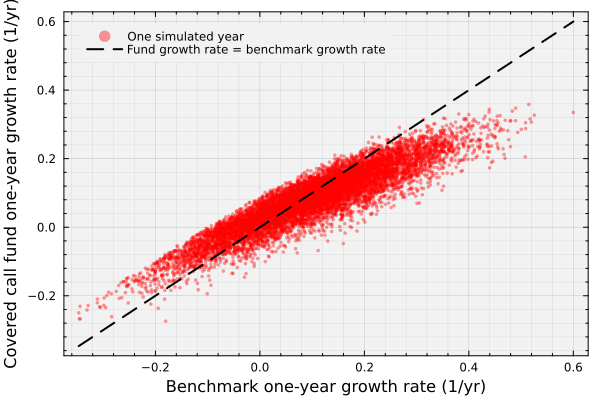

In [12]:
let

    # initialize: the range of the benchmark's growth rates, for the dashed line where the fund equals the benchmark -
    x = [minimum(benchmark_g), maximum(benchmark_g)]; # endpoints of the line (1/yr)

    # plot: one point per path -
    scatter(benchmark_g, fund_g, ms = 2, c = :red, msw = 0, alpha = 0.4, label = "One simulated year",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        xminorticks = true, yminorticks = true, minorgrid = true, legend = :topleft)
    plot!(x, x, lw = 2, c = :black, ls = :dash, label = "Fund growth rate = benchmark growth rate") # where the two growth rates are equal

    # labels -
    xlabel!("Benchmark one-year growth rate (1/yr)", fontsize = 18)
    ylabel!("Covered call fund one-year growth rate (1/yr)", fontsize = 18)
end

Your numbers will differ if you change the constants. Try `moneyness = 1.00` (at-the-money calls, more premium, less upside), `moneyness = 1.05`, or `σ_scale = 1.2`. Try `cash_reserve = 0.0` or `cash_reserve = 0.10` to see how the cash reserve changes how often the fund borrows.
___

## Summary
In this example, we simulated a fund that owns shares and sells one-month covered calls every month, and compared its one-year growth rate with that of a benchmark that holds the same shares and opens with the same cash but sells no calls.

> __Key Takeaways:__
>
> * __Monthly share prices from geometric Brownian motion:__ We simulated a year of monthly share prices with the drift and volatility estimated from historical data. These paths are our belief about the share price and give the range of outcomes the fund faces.
> * __A covered call fund rolls the lecture's covered call:__ Each month, we sold one call for every 100 shares at the first listed strike at or above our target strike, priced it on the binomial tree, and tracked the fund's shares and cash. When a call was exercised, the fund sold its shares at the strike and bought new shares from its cash, borrowing when the cash ran out.
> * __Covered call funds trade upside for a cushion:__ Compared with a benchmark holding the same shares and opening cash, the fund's one-year growth rates were less spread out and less often negative, but its best years were far below the benchmark's. Plotting one against the other showed a shape like the lecture's covered call profit diagram.

Funds such as FEPI sell covered calls on the stocks they own; this example shows the trade-off their investors accept.
___

## Disclaimer and Risks
__This content is offered solely for training and informational purposes__. No offer or solicitation to buy or sell securities or derivative products or any investment or trading advice or strategy is made, given, or endorsed by the teaching team.

__Trading involves risk__. Carefully review your financial situation before investing in securities, futures contracts, options, or commodity interests. Past performance, whether actual or indicated by historical tests of strategies, is no guarantee of future performance or success. Trading is generally inappropriate for someone with limited resources, investment or trading experience, or a low-risk tolerance. Only risk capital that is not required for living expenses should be used.

__You are fully responsible for any investment or trading decisions you make__. Such decisions should be based solely on evaluating your financial circumstances, investment or trading objectives, risk tolerance, and liquidity needs.

___